#### 3.3.2 Матрица ассоциаций

**Входы**

- Только train
- Смысловая классификация признаков

**Выходы**

- Матрица Pearson, Cramér’s V, Spearman, NMI и ε²
- Тепловая карта нижнего треугольника

**Что делаем**

Считаем уже выбранные меры для соответствующих типов пар, включая целевую переменную


In [ ]:
# Только для разработки: открыть раздел можно из notebooks/ или корня проекта
from pathlib import Path as _NotebookPath
import os as _notebook_os
_notebook_root = next(
    path for path in (_NotebookPath.cwd(), *_NotebookPath.cwd().parents)
    if (path / 'config/build/project.json').is_file()
)
_notebook_os.chdir(_notebook_root)


##### Попарный анализ ассоциаций — Pairwise Association Analysis

Рассчитываем связи всех переменных, включая `loan_status`, только на `train`, используя смысловую классификацию из предварительного анализа

###### Методы по сочетаниям типов

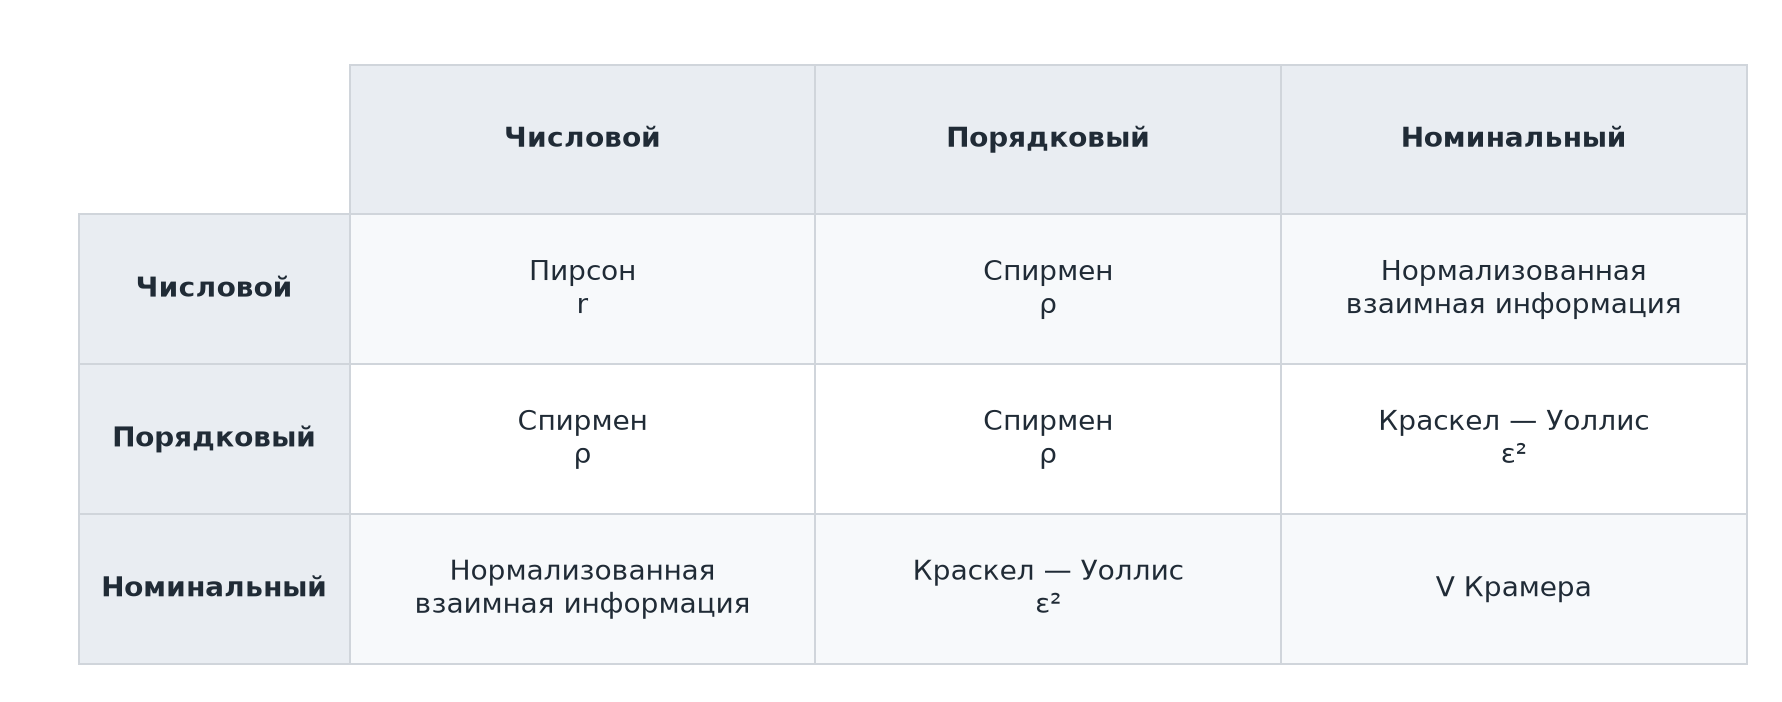

Для NMI используем I(X;Y) / H(Y), где Y — номинальная переменная независимо от расположения пары в таблице


Бинарные переменные считаем номинальными, порядок `loan_grade`: **A < B < C < D < E < F < G**

###### Кратко о методах

- **Pearson:** линейная связь, r ∈ [−1, 1], сила по |r|
- **Spearman:** монотонная связь по рангам с усреднением совпадений, ρ ∈ [−1, 1], сила по |ρ|
- **Cramér’s V:** ассоциация категорий по таблице сопряжённости и χ² без поправки Йейтса, V ∈ [0, 1]
- **NMI:** общая зависимость непрерывной и дискретной переменных, оценка `mutual_info_classif` с `n_neighbors=3`, `random_state=42`, без дискретизации X, нормализация на энтропию Y в натах, диапазон [0, 1]
- **Kruskal–Wallis, ε²:** различия рангов между номинальными группами, H с поправкой на совпадения, k — число групп, n — число наблюдений, зависимость при одинаковых средних рангах групп может остаться незамеченной

Пропуски исключаем отдельно для каждой пары, неопределённые коэффициенты оставляем `NaN`, включая нулевую энтропию Y для NMI и вырожденные группы для ε²

NMI — выборочная оценка: отношение ограничиваем [0, 1], исходную оценку сохраняем в `nmi_estimates`, для категорий с единственным наблюдением возвращаем `NaN`

Исходную ε² сохраняем в матрице и `kruskal_effects`, интервалом [0, 1] ограничиваем только окраску

Значения разных мер напрямую не сравниваем, нулевые оценки не доказывают независимость

###### Общие вычисления


In [ ]:
exec(compile(__import__('pathlib').Path('src/notebooks/03_analysis/03_correlations/_code/64_calculate_associations.py').read_text(encoding='utf-8'), 'src/notebooks/03_analysis/03_correlations/_code/64_calculate_associations.py', 'exec'), globals())


###### Матрица ассоциаций

Матрица данных симметрична, показываем только нижний треугольник с диагональю, подписи столбцов — снизу

Цвет и интенсивность задаются методом, числовые подписи сохраняют знак, неизвестные значения остаются пустыми, общей цветовой шкалы нет

В датасете один порядковый признак, поэтому для Ordinal × Ordinal рассчитывается только его самокорреляция, равная 1 при наличии разных наблюдаемых категорий


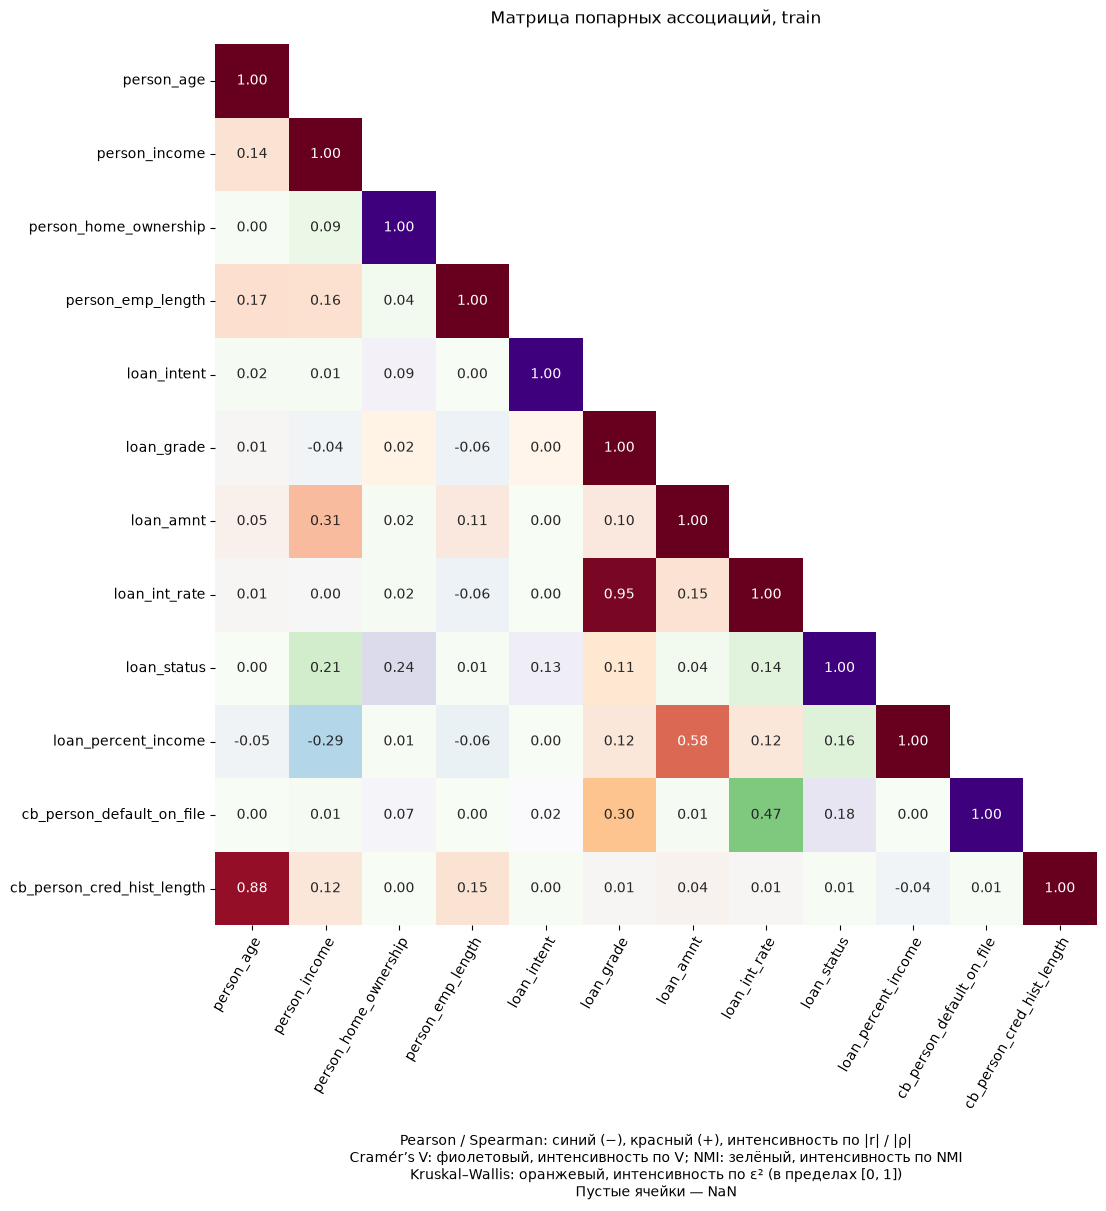

In [ ]:
exec(compile(__import__('pathlib').Path('src/notebooks/03_analysis/03_correlations/_code/66_plot_associations.py').read_text(encoding='utf-8'), 'src/notebooks/03_analysis/03_correlations/_code/66_plot_associations.py', 'exec'), globals())
